Select dataset option:
1 - CIFAR-10
2 - MNIST
3 - Upload your own image dataset (.zip)
Enter choice: 1
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Training shape: (50000, 32, 32, 3)
Test shape: (10000, 32, 32, 3)


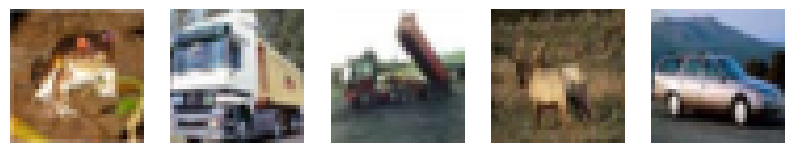

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import cifar10 , mnist
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from google.colab import files
import zipfile
from PIL import Image

print("Select dataset option:")
print("1 - CIFAR-10")
print("2 - MNIST")
print("3 - Upload your own image dataset (.zip)")
choice = int(input("Enter choice: "))

if choice == 1:
    (x_train, _), (x_test, _) = cifar10.load_data()
    img_shape = (32, 32, 3)

elif choice == 2:
    (x_train, _), (x_test, _) = mnist.load_data()
    x_train = np.expand_dims(x_train, -1)
    x_test = np.expand_dims(x_test, -1)
    img_shape = (28, 28, 1)

elif choice == 3:
    uploaded = files.upload()
    for fname in uploaded.keys():
        with zipfile.ZipFile(fname, 'r') as zip_ref:
            zip_ref.extractall("dataset")

    datagen = ImageDataGenerator(rescale=1.0/255.0, validation_split=0.2)
    train_gen = datagen.flow_from_directory(
        "dataset", target_size=(64, 64), batch_size=128, class_mode=None, subset="training")
    test_gen = datagen.flow_from_directory(
        "dataset", target_size=(64, 64), batch_size=128, class_mode=None, subset="validation")

    x_train = np.concatenate([train_gen.next() for _ in range(len(train_gen))])
    x_test = np.concatenate([test_gen.next() for _ in range(len(test_gen))])
    img_shape = (64, 64, 3)

else:
    raise ValueError("Invalid choice!")

x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Training shape:", x_train.shape)
print("Test shape:", x_test.shape)

n = 5
plt.figure(figsize=(10, 2))
for i in range(n):
  ax = plt.subplot(1, n, i+1)
  plt.imshow(x_train[i].squeeze(), cmap="gray" if img_shape[-1]==1 else None)
  plt.axis('off')
plt.show()

## Autoencoder ##

In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D
from tensorflow.keras.optimizers import Adam

input_img = Input(shape=img_shape)

x = Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
x = MaxPooling2D((2, 2), padding='same')(x)
x = Conv2D(16, (3, 3), activation='relu', padding='same')(x)
encoded = MaxPooling2D((2, 2), padding='same', name="bottleneck")(x)

x = Conv2D(16, (3, 3), activation='relu', padding='same')(encoded)
x = UpSampling2D((2, 2))(x)
x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = UpSampling2D((2, 2))(x)

decoded = Conv2D(img_shape[-1], (3, 3), activation='sigmoid', padding='same')(x)

autoencoder = Model(input_img, decoded)
autoencoder.compile(optimizer='adam', loss='mean_squared_error')

autoencoder.summary()

history = autoencoder.fit(x_train, x_train, epochs=20, batch_size=128, shuffle=True, validation_data=(x_test, x_test))

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (MaxPooling2D)       │ (None, 8, 8, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 16)       │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,347 (52.14 KB)

 Trainable params: 13,347 (52.14 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - loss: 0.0239 - val_loss: 0.0080
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0074 - val_loss: 0.0066
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 0.0064 - val_loss: 0.0059
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.0059 - val_loss: 0.0060
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.0056 - val_loss: 0.0054
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.0053 - val_loss: 0.0052
Epoch 7/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 0.0051 - val_loss: 0.0049
Epoch 8/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 0.0049 - val_loss: 0.0048
Epoch 9/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0047 - val_loss: 0.0045
Epoch 10/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.0046 - val_loss: 0.0045
Epoch 11/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 0.0045 - val_loss: 0.0043
Epoch 12/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/st

## Image Compression ##


In [ ]:
bottleneck_layer = autoencoder.get_layer("bottleneck").output
encoder = Model(inputs=autoencoder.input, outputs=bottleneck_layer)

encoded_imgs = encoder.predict(x_test)

print("Original shape:", x_test.shape)
print("Encoded shape:", encoded_imgs.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
Original shape: (10000, 32, 32, 3)
Encoded shape: (10000, 8, 8, 16)


## Feature extraction ##

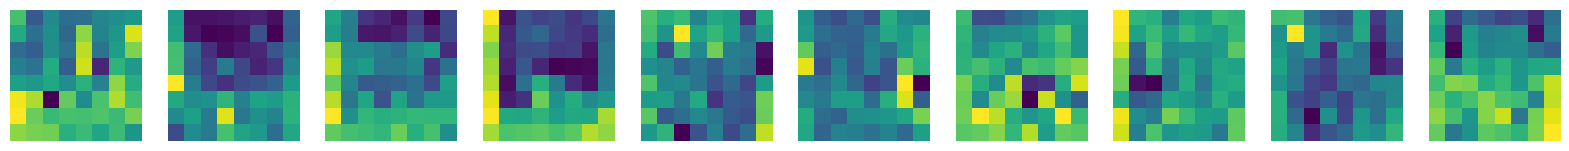

In [ ]:
n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
  ax = plt.subplot(1, n, i + 1)
  plt.imshow(encoded_imgs[i, :, :, 0], cmap='viridis')
  plt.axis('off')
plt.show()

## Evaluation & Reconstruction ##

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


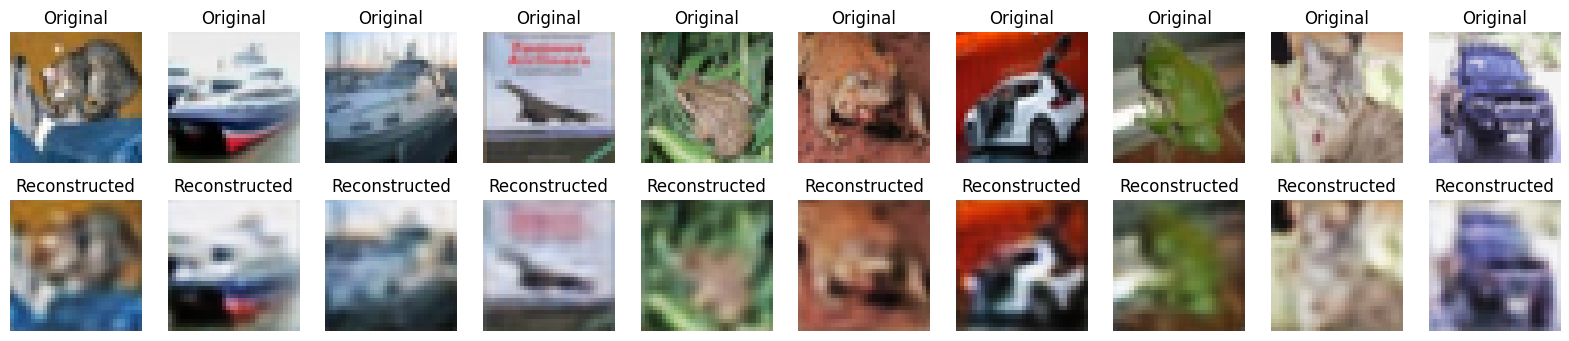

Average MSE: 0.003665
Average PSNR: 24.94 dB
Average SSIM: 0.8123


In [ ]:
from sklearn.metrics import mean_squared_error

decoded_imgs = autoencoder.predict(x_test)

n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    # Original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray" if img_shape[-1]==1 else None)
    plt.title("Original")
    plt.axis('off')

    # Reconstructed
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].squeeze(), cmap="gray" if img_shape[-1]==1 else None)
    plt.title("Reconstructed")
    plt.axis('off')
plt.show()


mse_val = np.mean([mean_squared_error(x_test[i].flatten(), decoded_imgs[i].flatten()) for i in range(len(x_test))])
psnr_val = tf.image.psnr(decoded_imgs, x_test, max_val=1.0).numpy().mean()
ssim_val = tf.image.ssim(decoded_imgs, x_test, max_val=1.0).numpy().mean()

print(f"Average MSE: {mse_val:.6f}")
print(f"Average PSNR: {psnr_val:.2f} dB")
print(f"Average SSIM: {ssim_val:.4f}")

## Save Encoded Features ##

In [ ]:
os.makedirs("saved_features", exist_ok=True)

np.save("saved_features/encoded_features.npy", encoded_imgs)
np.save("saved_features/original_images.npy", x_test)

print("Encoded features saved to 'saved_features/encoded_features.npy'")
print("Original images saved to 'saved_features/original_images.npy'")

loaded_features = np.load("saved_features/encoded_features.npy")
print("Loaded features shape:", loaded_features.shape)


Encoded features saved to 'saved_features/encoded_features.npy'
Original images saved to 'saved_features/original_images.npy'
Loaded features shape: (10000, 8, 8, 16)


## K-Means Clustering & t-SNE Visualisation ##

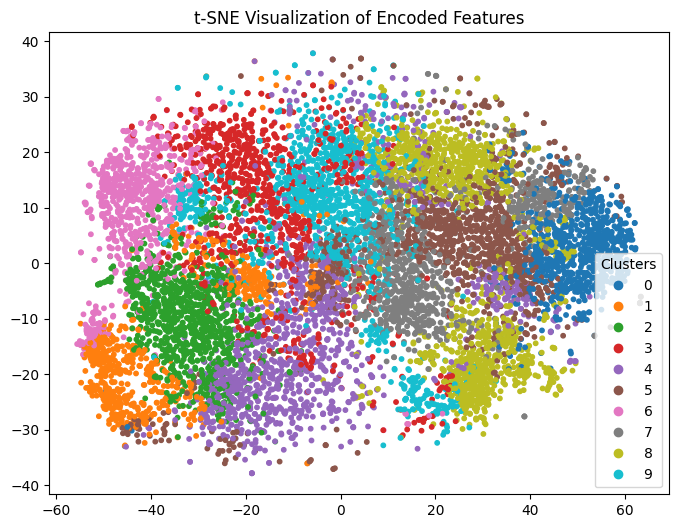

In [ ]:
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE

features_flat = encoded_imgs.reshape(encoded_imgs.shape[0], -1)

n_clusters = 10
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(features_flat)

np.save("saved_features/cluster_labels.npy", cluster_labels)

tsne = TSNE(n_components=2, random_state=42, perplexity=30, learning_rate=200)
features_2d = tsne.fit_transform(features_flat)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(features_2d[:, 0], features_2d[:, 1], c=cluster_labels, cmap='tab10', s=10)
plt.legend(*scatter.legend_elements(), title="Clusters")
plt.title("t-SNE Visualization of Encoded Features")
plt.show()

## Sample Images ##

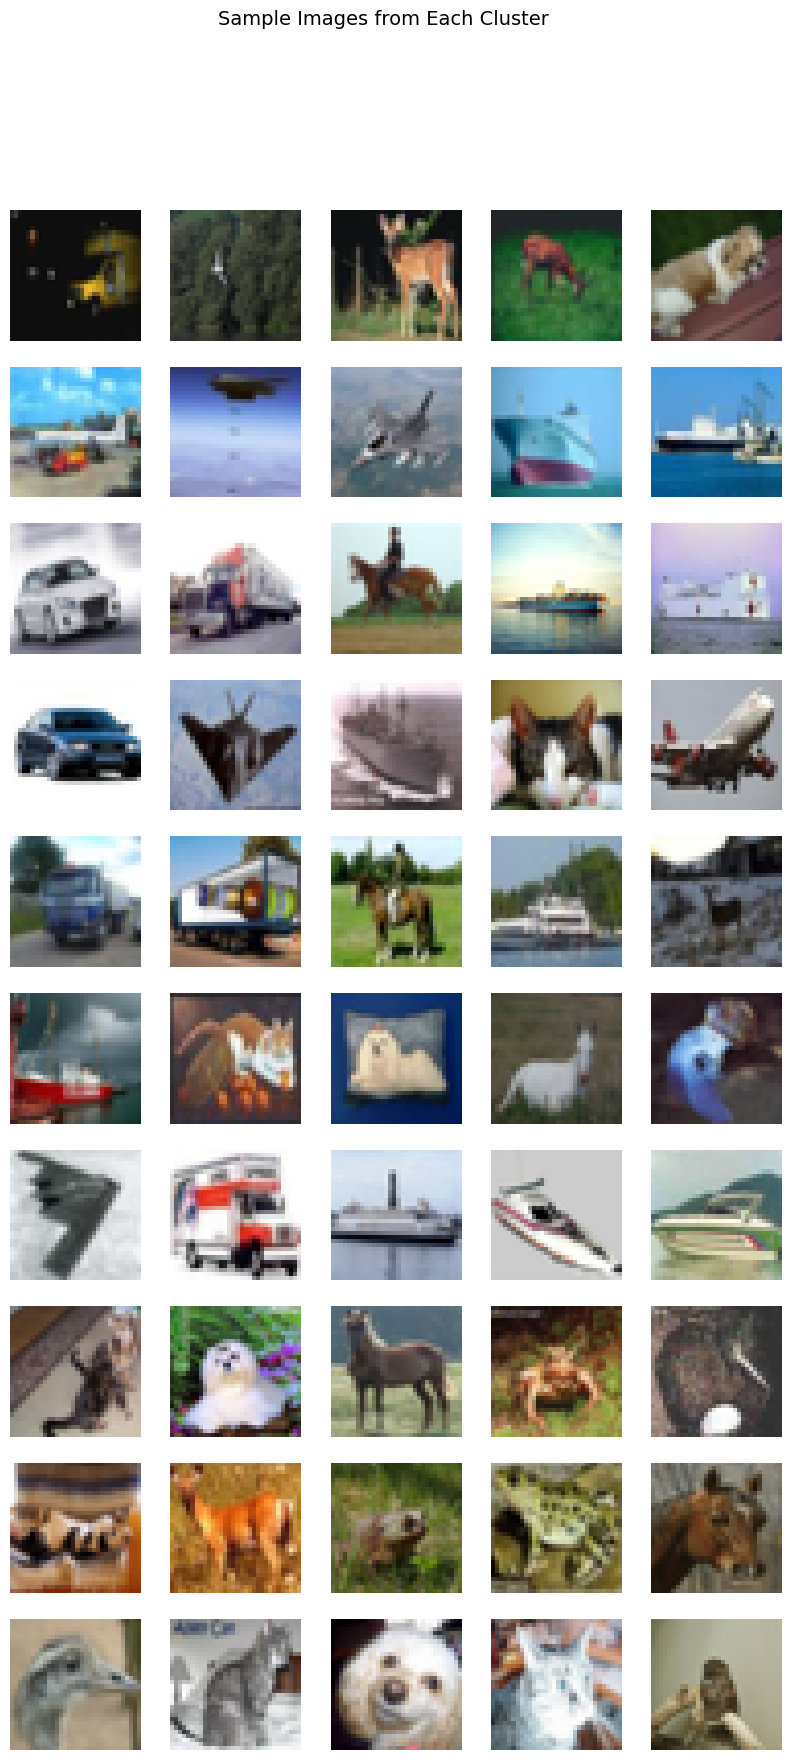

In [ ]:
samples_per_cluster = 5
plt.figure(figsize=(samples_per_cluster*2, n_clusters*2))

for cluster in range(n_clusters):
    cluster_indices = np.where(cluster_labels == cluster)[0]
    if len(cluster_indices) < samples_per_cluster:
        continue
    selected_indices = np.random.choice(cluster_indices, size=samples_per_cluster, replace=False)

    for i, idx in enumerate(selected_indices):
        plt.subplot(n_clusters, samples_per_cluster, cluster * samples_per_cluster + i + 1)
        plt.imshow(x_test[idx].squeeze(), cmap="gray" if img_shape[-1]==1 else None)
        plt.axis('off')
        if i == 0:
            plt.ylabel(f"Cluster {cluster}", fontsize=10)

plt.suptitle("Sample Images from Each Cluster", fontsize=14)
plt.show()